# 購買回数だけで、ブランドの状態を判断できるか

## 概要

『マーケティングサイエンスの理論と実践』第5章「消費財の購買行動をモデル化する」では、購買回数とブランド選択を確率分布で表す。この記事では、ロイヤルティ指標の読み方、負の二項分布（NBD）の導出、ディリクレ分布との組み合わせ、Pythonによる推定と比較を、本章と同じ順に紹介する。

### 実行環境

仮想環境とカーネルの表示名は **wa-src(3.14.6)**、Pythonは **3.14.6** である。NumPy、SciPy、Matplotlib、IPythonを使う。上から順に実行すれば、外部データなしで再現できる。グラフは`05_nb_files`にSVGで保存し、出力欄にも埋め込む。数値の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
from base64 import b64encode
from importlib.metadata import version
from io import BytesIO
from pathlib import Path
from pprint import pprint
import platform

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter, MaxNLocator, ScalarFormatter
import numpy as np
from scipy import optimize, special, stats
from IPython.display import Latex, display

# ノートブックのフォルダー、またはリポジトリ直下から実行する。
base = Path.cwd()
if (base / "blog/05/05_nb.ipynb").exists():
    base = base / "blog/05"
FIG_DIR = base / "05_nb_files"
FIG_DIR.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残して有効数字3桁にする。整数の回数は整数で扱う。"""
    return format(float(value), "#.3g").removesuffix(".")


def show_math(tex):
    r"""重要式の \( ... \) を、表示用の $$ ... $$ に変換する。"""
    tex = tex.strip()
    if tex.startswith(r"\(") and tex.endswith(r"\)"):
        tex = tex[2:-2].strip()
    display(Latex("$$\n" + tex + "\n$$"))


def save_svg(fig, filename):
    """SVGを保存し、ダウンロード後も見られるよう出力に埋め込む。"""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(FuncFormatter(
                    lambda value, _: str(int(value))
                    if float(value).is_integer() else sig3(value)
                ))
    path = FIG_DIR / filename
    fig.savefig(path, format="svg", bbox_inches="tight")
    # SVGに対応しないビューアー向けのPNGは、ファイルにせず出力だけに含める。
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    display({"image/svg+xml": path.read_text(encoding="utf-8"),
             "image/png": b64encode(preview.getvalue()).decode("ascii")}, raw=True)


np.set_printoptions(formatter={"float_kind": sig3})
fonts = {font.name for font in font_manager.fontManager.ttflist}
for candidate in ("Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "Yu Gothic"):
    if candidate in fonts:
        plt.rcParams["font.family"] = candidate
        break
plt.rcParams.update({"font.size": 11, "axes.unicode_minus": False,
                     "svg.fonttype": "path", "svg.hashsalt": "blog05"})
COLORS = ["#3274A1", "#D58B27", "#419578"]

print("仮想環境：wa-src(3.14.6)")
print(f"Python：{platform.python_version()} / OS：{platform.system()}")
for package in ("numpy", "scipy", "matplotlib", "ipython"):
    print(f"{package}：{version(package)}")

仮想環境：wa-src(3.14.6)
Python：3.14.6 / OS：Darwin
numpy：2.4.6
scipy：1.18.1
matplotlib：3.11.2
ipython：9.18.1


## 1. ロイヤルティ指標をどう読むか

繰り返し買う顧客を増やしたい。本章は、この実務上の課題から始まる。紹介される事例では、ロイヤル層の月間平均購買回数は3.10回から3.30回へ増えたが、ブランド全体の売上はほぼ変わらなかった。企業や数値の一部を変更した事例であり、比較対象がないため施策の効果は判断できない。

市場シェアの小さいブランドは、期間内に一度でも買う人の割合である「期間浸透率」が低く、買った人1人当たりの平均購買回数もやや少ない。この傾向をダブルジョパディという。平均回数が競合より少ないだけでは、顧客の愛着が弱いとは言えない。私は、まず何人に買われ、その人たちが何回買ったかを分けるほうが、状況を理解しやすいと考える。

## 2. 購買回数をNBDで表す

### 個人の購買と、個人間の違い

一定期間の購買回数を$X$、その人の期待購買回数を$\mu$とする。個人内では購買が独立に、一定の率で起こると仮定し、ポアソン分布を使う。ところが、全員に同じ$\mu$を置くと、低頻度層と高頻度層の違いを表せない。そこで$\mu$をガンマ分布に従わせる。$r$は形状、$\lambda$は率であり、尺度は$1/\lambda$である。

In [2]:
show_math(r"""\(
\begin{aligned}
X\mid\mu&\sim\operatorname{Poisson}(\mu), &
P(X=x\mid\mu)&=\frac{e^{-\mu}\mu^x}{x!},\quad x=0,1,\ldots,\\
\mathbb{E}[X\mid\mu]&=\mu, & \operatorname{Var}(X\mid\mu)&=\mu,\\
\mu&\sim\operatorname{Gamma}(r,\lambda), &
f(\mu)&=\frac{\lambda^r}{\Gamma(r)}\mu^{r-1}e^{-\lambda\mu},\quad\mu>0,\\
\mathbb{E}[\mu]&=\frac r\lambda, & \operatorname{Var}(\mu)&=\frac r{\lambda^2}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

### 観察できない期待回数を積分する

各$\mu$での購買確率を、その$\mu$が現れる密度で重み付けして平均する。指数とべき乗をまとめ、$t=(1+\lambda)\mu$と変数変換する。最後にガンマ関数の定義を使うとNBDになる。

In [3]:
show_math(r"""\(
\begin{aligned}
P(X=x)
&=\int_0^\infty P(X=x\mid\mu)f(\mu)\,d\mu\\
&=\int_0^\infty\frac{e^{-\mu}\mu^x}{x!}
  \frac{\lambda^r\mu^{r-1}e^{-\lambda\mu}}{\Gamma(r)}\,d\mu\\
&=\frac{\lambda^r}{\Gamma(r)x!}
  \int_0^\infty\mu^{x+r-1}e^{-(1+\lambda)\mu}\,d\mu.\\
t&=(1+\lambda)\mu,\quad\mu=\frac{t}{1+\lambda},\quad
d\mu=\frac{dt}{1+\lambda},\\
P(X=x)
&=\frac{\lambda^r}{\Gamma(r)x!}
  \int_0^\infty\left(\frac{t}{1+\lambda}\right)^{x+r-1}
  e^{-t}\frac{dt}{1+\lambda}\\
&=\frac{\lambda^r}{\Gamma(r)x!(1+\lambda)^{x+r}}
  \underbrace{\int_0^\infty t^{x+r-1}e^{-t}\,dt}_{\Gamma(x+r)}\\
&=\frac{\Gamma(x+r)}{\Gamma(r)x!}
  \left(\frac{\lambda}{1+\lambda}\right)^r
  \left(\frac{1}{1+\lambda}\right)^x.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

### 平均、分散、期間浸透率に読み替える

本文の実装に合わせ、$M=r/\lambda$、$K=r$と置く。$M$は0回購買者を含む平均回数である。全体の分散は、個人内の分散の平均と、個人間の平均の分散を足して求める。$M$を固定すると、$K$が小さいほどばらつきが大きい。

In [4]:
show_math(r"""\(
\begin{aligned}
\lambda&=K/M,\quad
\frac{\lambda}{1+\lambda}=\frac{K}{K+M},\quad
\frac{1}{1+\lambda}=\frac{M}{K+M},\\
P(X=x\mid M,K)&=\frac{\Gamma(x+K)}{\Gamma(K)x!}
\left(\frac K{K+M}\right)^K\left(\frac M{K+M}\right)^x,\\
\mathbb{E}[X]&=\mathbb{E}[\mathbb{E}[X\mid\mu]]
=\mathbb{E}[\mu]=r/\lambda=M,\\
\operatorname{Var}(X)&=\mathbb{E}[\operatorname{Var}(X\mid\mu)]
+\operatorname{Var}(\mathbb{E}[X\mid\mu])\\
&=\mathbb{E}[\mu]+\operatorname{Var}(\mu)
=\frac r\lambda+\frac r{\lambda^2}=M+\frac{M^2}{K}.
\end{aligned}
\)""")

show_math(r"""\(
\begin{aligned}
P(X=0)&=\frac{\Gamma(K)}{\Gamma(K)\,0!}
\left(\frac K{K+M}\right)^K\left(\frac M{K+M}\right)^0
=\left(\frac K{K+M}\right)^K,\\
b&=P(X\geq1)=1-P(X=0),\\
w&=\mathbb{E}[X\mid X\geq1]
=\sum_{x=1}^\infty x\frac{P(X=x)}b
=\frac{\mathbb{E}[X]}b=\frac Mb,\qquad M=bw.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

$b$はカテゴリの期間浸透率、$w$はカテゴリを買った人1人当たりの平均購買回数である。NBDはこの二つを同じ分布から計算できる。ただし、購買率の安定性を仮定するため、強い季節性や生活環境の変化がある期間では適合を確認する必要がある。

## 3. どのブランドを選ぶか

### ディリクレ分布と多項分布を組み合わせる

カテゴリの購買回数を$N_i$、ブランド別の回数を$\mathbf{X}_i$とする。選択確率のベクトル$\mathbf{p}_i$にはディリクレ分布を使う。以下ではパラメータのベクトルを$\mathbf{a}=(\alpha_1,\ldots,\alpha_J)$と書く。カテゴリの期待回数$\mu_i$と$\mathbf{p}_i$は独立と仮定する。

In [5]:
show_math(r"""\(
\begin{aligned}
\mu_i&\sim\operatorname{Gamma}(K,K/M),\quad
N_i\mid\mu_i\sim\operatorname{Poisson}(\mu_i),\\
\mathbf{p}_i&\sim\operatorname{Dirichlet}(\mathbf{a}),\quad
\alpha_0=\sum_{j=1}^J\alpha_j,\quad\sum_jp_{ij}=1,\\
f(\mathbf{p}_i\mid\mathbf{a})
&=\frac{\Gamma(\alpha_0)}{\prod_j\Gamma(\alpha_j)}
\prod_jp_{ij}^{\alpha_j-1},\\
\mathbf{X}_i\mid N_i=n,\mathbf{p}_i&\sim\operatorname{Multinomial}(n,\mathbf{p}_i),\\
P(\mathbf{X}_i=\mathbf{x}_i\mid n,\mathbf{p}_i)
&=\frac{n!}{\prod_jx_{ij}!}\prod_jp_{ij}^{x_{ij}},\quad\sum_jx_{ij}=n,\\
s_j&=\mathbb{E}[p_{ij}]=\frac{\alpha_j}{\alpha_0},\qquad
\operatorname{Var}(p_{ij})=\frac{s_j(1-s_j)}{\alpha_0+1},\\
M_j&=\mathbb{E}[X_{ij}]=\mathbb{E}[\mu_ip_{ij}]
=\mathbb{E}[\mu_i]\mathbb{E}[p_{ij}]=Ms_j.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

$s_j$は購買回数ベースの市場シェアである。同じシェアでも、$\alpha_0$が小さいほど個人の選択確率に偏りが出る。本文では、選択確率を積分したディリクレ多項分布とNBDの積から、ブランド別回数の同時分布も導いている。

### ブランドを一度も買わない確率から求める

ブランド$j$の選択確率を$p$に固定すると、$n$回すべてで選ばない確率は$(1-p)^n$となる。これをポアソン分布、ガンマ分布、最後に$p$のベータ分布で順に平均する。

In [6]:
show_math(r"""\(
\begin{aligned}
P(X_{ij}=0\mid\mu,p)
&=\sum_{n=0}^\infty(1-p)^n\frac{e^{-\mu}\mu^n}{n!}
=e^{-\mu}e^{\mu(1-p)}=e^{-\mu p},\\
P(X_{ij}=0\mid p)
&=\frac{(K/M)^K}{\Gamma(K)}
\int_0^\infty\mu^{K-1}e^{-(K/M+p)\mu}\,d\mu\\
&=\frac{(K/M)^K}{\Gamma(K)}\frac{\Gamma(K)}{(K/M+p)^K}
=\left(\frac K{K+Mp}\right)^K.
\end{aligned}
\)""")

show_math(r"""\(
\begin{aligned}
p_{ij}&\sim\operatorname{Beta}(\alpha_j,\alpha_0-\alpha_j),\qquad
B(a,b)=\frac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)},\\
P(X_{ij}=0)
&=\frac{\displaystyle\int_0^1(1+Mp/K)^{-K}
p^{\alpha_j-1}(1-p)^{\alpha_0-\alpha_j-1}\,dp}
{B(\alpha_j,\alpha_0-\alpha_j)}\\
&={}_2F_1\!\left(K,\alpha_j;\alpha_0;-M/K\right),\\
b_j&=1-P(X_{ij}=0),\qquad w_j=\frac{M_j}{b_j}=\frac{Ms_j}{b_j}.
\end{aligned}
\)""")

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

途中のガンマ積分は前節と同じ変数変換を使う。最後のベータ積分をガウスの超幾何関数${}_2F_1$で表している。$M,K,\alpha_0$を固定して比較すると、小さいシェアに低い$b_j$と低い$w_j$が対応する。

また、観察期間に一つのブランドしか買わなくても、選択確率が1とは限らない。たとえば$p=0.600$なら、2回ともそのブランドを選ぶ確率は$0.600^2=0.360$である。有限期間の「100%ロイヤル」と、常に同じブランドを選ぶ好みは区別する。

## 4. Pythonで推定し、結果を比べる

### 0回購買者を含めてデータを作る

実務では、顧客マスターに購買回数を左結合し、履歴のない対象者も0回として残す。対象者全員の観察期間をそろえ、数量ではなく購買機会を数える。会員だけのデータなら、浸透率の分母も会員である。

以下は本文と同じ乱数シード42、500人、1年間、3ブランドの模擬データである。$M=3.00$、$K=0.800$、$\alpha_0=10$、平均シェアは50%、30%、20%とする。NumPyのガンマ分布には、率の逆数である尺度$M/K$を渡す。

{'0回購買者数': 145, '不偏分散': '13.1', '対象者数': 500, '平均回数': '2.82'}
先頭5人のブランド別購買回数（列：A、B、C）
array([[1, 7, 0],
       [1, 6, 0],
       [0, 0, 0],
       [3, 1, 0],
       [0, 0, 0]])


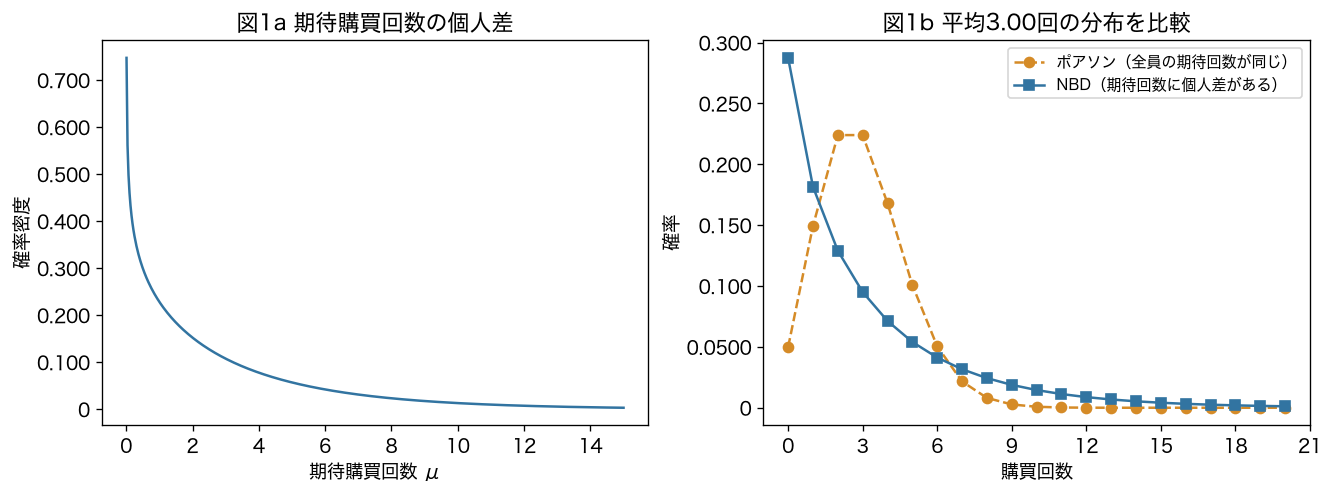

In [7]:
rng = np.random.default_rng(42)
M_true, K_true, alpha0 = 3.00, 0.800, 10
shares_true = np.array([0.500, 0.300, 0.200])
brands = ["A", "B", "C"]
n_people = 500

# 元ノートブックと同じ順番で乱数を生成する。
mu = rng.gamma(shape=K_true, scale=M_true / K_true, size=n_people)
x = rng.poisson(mu)
probabilities = rng.dirichlet(alpha0 * shares_true, size=n_people)
brand_counts = np.zeros((n_people, len(brands)), dtype=int)
for i, total in enumerate(x):
    # 0回の対象者も行を残す。1購買機会につき1ブランドを選ぶ設定。
    if total > 0:
        choices = rng.choice(len(brands), size=int(total), p=probabilities[i])
        brand_counts[i] = np.bincount(choices, minlength=len(brands))

pprint({"対象者数": n_people, "0回購買者数": int(np.sum(x == 0)),
        "平均回数": sig3(x.mean()), "不偏分散": sig3(x.var(ddof=1))})
print("先頭5人のブランド別購買回数（列：A、B、C）")
pprint(brand_counts[:5])

# 図1：生成に使った分布。同じ平均でも、NBDは0回と高頻度側が多い。
grid = np.linspace(0.0100, 15, 500)
counts_grid = np.arange(21)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(grid, stats.gamma.pdf(grid, K_true, scale=M_true / K_true),
             color=COLORS[0])
axes[0].set(title="図1a 期待購買回数の個人差", xlabel="期待購買回数 μ", ylabel="確率密度")
axes[1].plot(counts_grid, stats.poisson.pmf(counts_grid, M_true), "o--",
             color=COLORS[1], label="ポアソン（全員の期待回数が同じ）")
axes[1].plot(counts_grid, stats.nbinom.pmf(counts_grid, K_true, K_true / (K_true + M_true)),
             "s-", color=COLORS[0], label="NBD（期待回数に個人差がある）")
axes[1].set(title="図1b 平均3.00回の分布を比較", xlabel="購買回数", ylabel="確率")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].legend(fontsize=9)
save_svg(fig, "01_generating_distributions.svg")

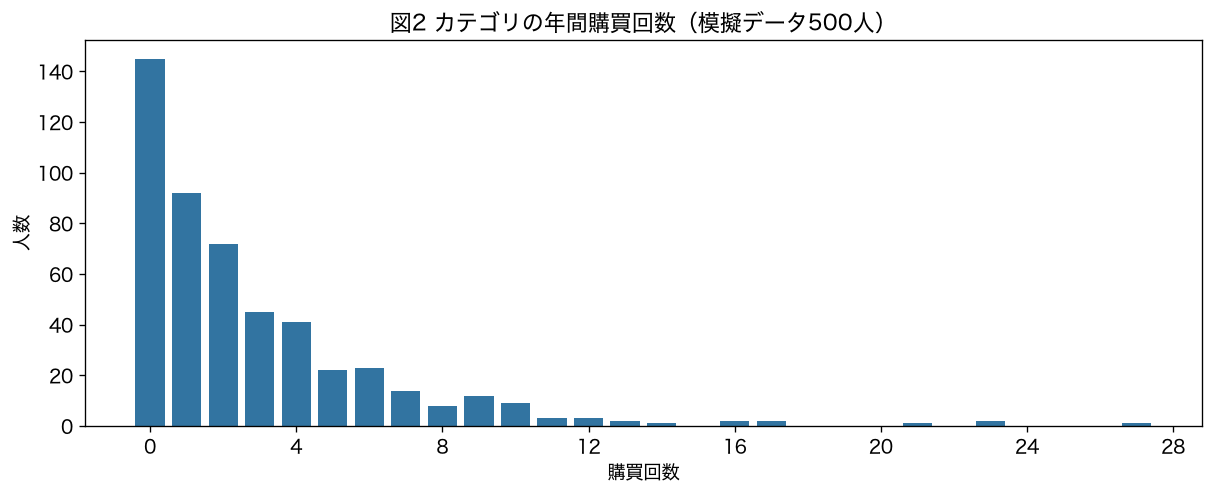

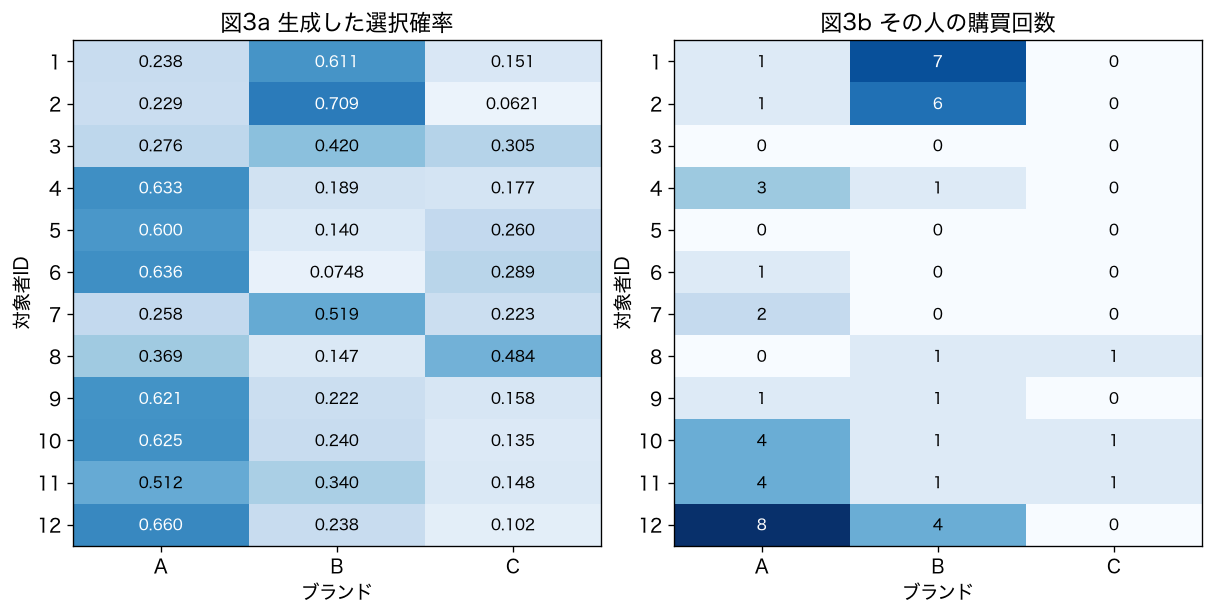

In [8]:
# 図2：0回の対象者を含む実測度数。ここでの実測は模擬データの集計を指す。
observed_counts = np.bincount(x)
x_values = np.arange(len(observed_counts))
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(x_values, observed_counts, color=COLORS[0])
ax.set(title="図2 カテゴリの年間購買回数（模擬データ500人）",
       xlabel="購買回数", ylabel="人数")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_svg(fig, "02_category_counts.svg")

# 図3：同じ12人について、潜在的な選択確率と観測された回数を並べる。
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
for ax, values, title, integer in (
    (axes[0], probabilities[:12], "図3a 生成した選択確率", False),
    (axes[1], brand_counts[:12], "図3b その人の購買回数", True),
):
    vmax = max(float(values.max()), 1)
    ax.imshow(values, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set(xticks=range(3), xticklabels=brands,
           yticks=range(12), yticklabels=range(1, 13),
           xlabel="ブランド", ylabel="対象者ID", title=title)
    for (row, col), value in np.ndenumerate(values):
        label = str(int(value)) if integer else sig3(value)
        ax.text(col, row, label, ha="center", va="center", fontsize=9,
                color="white" if value > vmax * 0.550 else "black")
save_svg(fig, "03_individual_brand_choices.svg")

0回購買者は145人で、平均は2.82回、不偏分散は13.1である。分散が平均を上回る。図3の左は生成時に使った確率で、実データから直接観察できる値ではない。右では0回の人や、一つのブランドだけ買った人も現れる。

### 最尤推定でMとKを求める

標本平均$\bar{x}$と不偏分散$v$から初期値を作り、対数尤度を最大化する。通常のモーメント法の分散とは分母が異なるが、ここでは本文に合わせて初期値に使う。正の値を保つため、$\log M$と$\log K$を最適化する。

In [9]:
show_math(r"""\(
\begin{aligned}
\bar{x}&=\frac1n\sum_i x_i,\qquad
v=\frac1{n-1}\sum_i(x_i-\bar{x})^2,\\
\widetilde{M}&=\bar{x},\quad
v=\bar{x}+\frac{\bar{x}^2}{\widetilde{K}}
\ \Rightarrow\ v-\bar{x}=\frac{\bar{x}^2}{\widetilde{K}}
\ \Rightarrow\ \widetilde{K}=\frac{\bar{x}^2}{v-\bar{x}},\\
\ell(M,K\mid\mathbf{x})&=\sum_i\log P(X=x_i\mid M,K)\\
&=\sum_i\left[\log\Gamma(x_i+K)-\log\Gamma(K)-\log\Gamma(x_i+1)\right.\\
&\hspace{3em}\left.+K\log\frac{K}{K+M}+x_i\log\frac{M}{K+M}\right].
\end{aligned}
\)""")

<IPython.core.display.Latex object>

{'推定K': '0.833', '推定M': '2.82', '最適化成功': True}


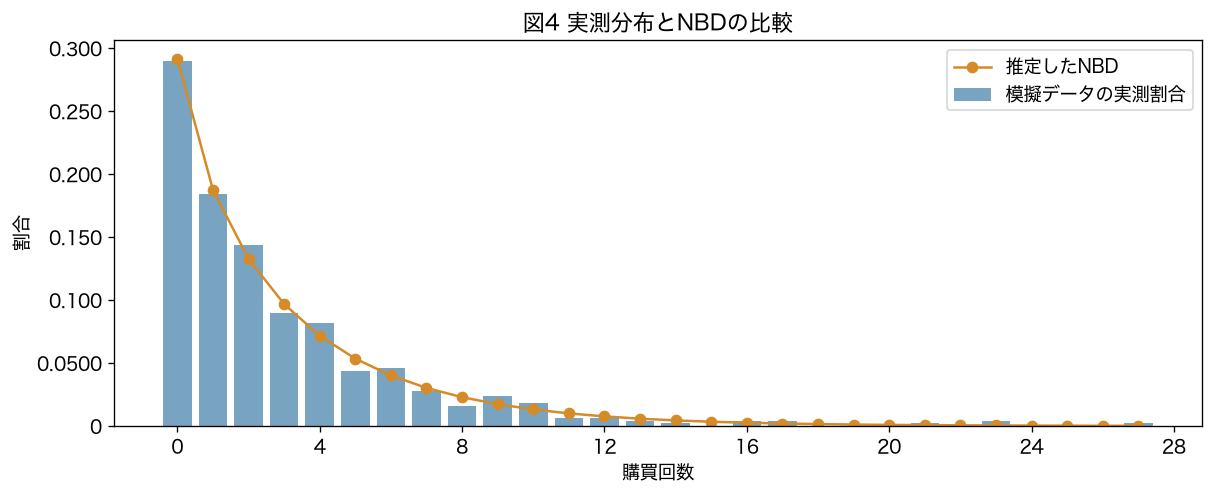

In [10]:
def nbd_logpmf(values, M, K):
    """大きな階乗を直接計算せず、対数ガンマ関数で確率を求める。"""
    return (special.gammaln(values + K) - special.gammaln(K)
            - special.gammaln(values + 1)
            + K * np.log(K / (K + M))
            + values * np.log(M / (K + M)))


def negative_loglik(log_parameters):
    M, K = np.exp(log_parameters)
    return -np.sum(nbd_logpmf(x, M, K))


mean, variance = x.mean(), x.var(ddof=1)
K_init = mean**2 / (variance - mean) if variance > mean else 1.00
result = optimize.minimize(
    negative_loglik, np.log([mean, max(K_init, 0.100)]),
    method="Nelder-Mead",
    options={"xatol": 1.00e-6, "fatol": 1.00e-6, "maxiter": 10000},
)
if not result.success:
    raise RuntimeError(f"最適化が収束しなかった：{result.message}")

M_hat, K_hat = np.exp(result.x)
pprint({"推定M": sig3(M_hat), "推定K": sig3(K_hat),
        "最適化成功": bool(result.success)})

fitted = np.exp(nbd_logpmf(x_values, M_hat, K_hat))
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(x_values, observed_counts / n_people, color=COLORS[0], alpha=0.650,
       label="模擬データの実測割合")
ax.plot(x_values, fitted, "o-", color=COLORS[1], label="推定したNBD")
ax.set(title="図4 実測分布とNBDの比較", xlabel="購買回数", ylabel="割合")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()
save_svg(fig, "04_nbd_fit.svg")

推定結果は$\hat{M}=2.82$、$\hat{K}=0.833$となる。設定値と完全には一致しないが、これは500人を無作為に生成した一例である。

### 当てはまりを検定する

期待人数が少ない高頻度側をまとめ、最後は「11回以上」とする。観測最大値を超える確率も含め、人数の合計を合わせる。区間数を$L$とし、自由度から推定した2パラメータ分を引く。

In [11]:
show_math(r"""\(
Q=\sum_{h=1}^L\frac{(O_h-E_h)^2}{E_h},\qquad
\nu=L-1-2,\qquad p_{\mathrm{test}}=P(\chi^2_\nu\geq Q).
\)""")

<IPython.core.display.Latex object>

{'p値': '0.650', 'カイ二乗統計量': '6.87', '区間数': 12, '最後の区間': '11回以上', '自由度': 9}


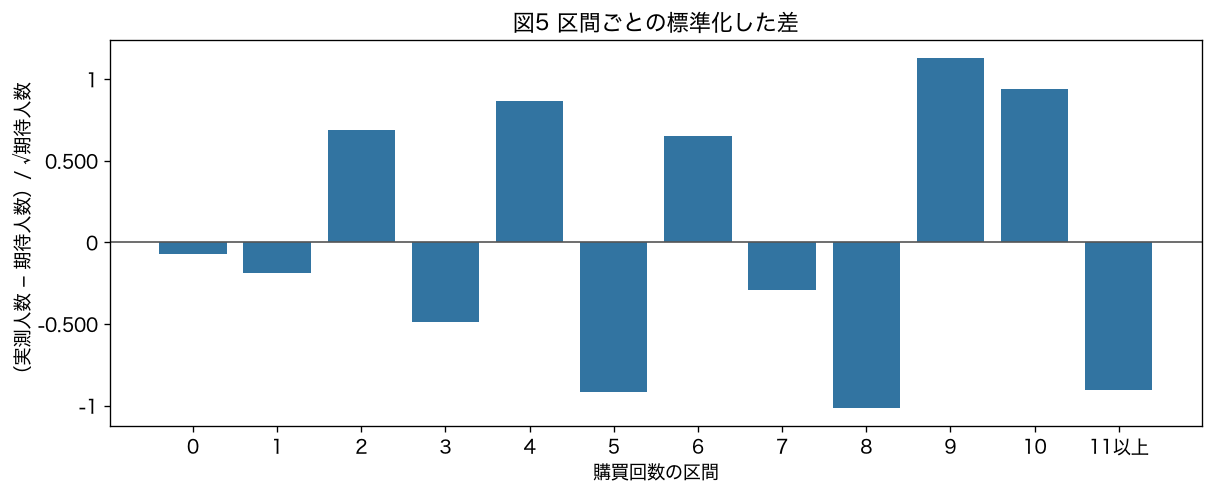

In [12]:
success_prob = K_hat / (K_hat + M_hat)
expected = fitted * n_people
cutoff = int(x.max())
while cutoff > 1 and expected[cutoff] < 5:
    cutoff -= 1

obs_grouped = np.r_[observed_counts[:cutoff], observed_counts[cutoff:].sum()]
tail = stats.nbinom.sf(cutoff - 1, K_hat, success_prob) * n_people
exp_grouped = np.r_[expected[:cutoff], tail]
degrees = len(obs_grouped) - 1 - 2
if degrees <= 0 or np.any(exp_grouped < 5):
    raise ValueError("区間のまとめ方を見直す必要がある")

chi2_value = np.sum((obs_grouped - exp_grouped)**2 / exp_grouped)
p_value = stats.chi2.sf(chi2_value, degrees)
pprint({"最後の区間": f"{cutoff}回以上", "区間数": len(obs_grouped),
        "自由度": degrees, "カイ二乗統計量": sig3(chi2_value),
        "p値": sig3(p_value)})

# 各区間の差を期待人数の平方根で割り、偏りの位置を確認する。
residuals = (obs_grouped - exp_grouped) / np.sqrt(exp_grouped)
labels = [str(i) for i in range(cutoff)] + [f"{cutoff}以上"]
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(labels, residuals, color=COLORS[0])
ax.axhline(0, color="#555555", linewidth=1)
ax.set(title="図5 区間ごとの標準化した差", xlabel="購買回数の区間",
       ylabel="（実測人数 − 期待人数）/ √期待人数")
save_svg(fig, "05_fit_residuals.svg")

統計量は6.87、自由度は9、$p$値は0.650となる。5%水準でNBDとの差は有意ではない。ただし、適合の証明ではなく、今回はNBDから生成したデータでの確認である。

### ブランド別の実測値と比較する

本文の実装ではディリクレのパラメータを推定せず、実測シェアと共通の$\hat{K}$を使う簡略モデルを採用する。選択確率の個人差を平均シェアに置き換えるため、前節のディリクレNBDとは異なる。以下の理論値は、この簡略モデルの比較基準である。

In [13]:
show_math(r"""\(
\widehat{s}_j=\frac{\sum_i X_{ij}}{\sum_iN_i},\quad
\widehat{M}_j=\widehat{M}\widehat{s}_j,\quad
b_j^{\mathrm{simple}}=1-\left(\frac{\widehat{K}}
{\widehat{K}+\widehat{M}_j}\right)^{\widehat{K}},\quad
w_j^{\mathrm{simple}}=\frac{\widehat{M}_j}{b_j^{\mathrm{simple}}}.
\)""")

<IPython.core.display.Latex object>

{'シェア（%）': '51.0',
 'ブランド': 'A',
 '浸透率：実測 / 簡略理論（%）': ['54.6', '56.7'],
 '購買者当たり回数：実測 / 簡略理論': ['2.64', '2.54']}
{'シェア（%）': '29.0',
 'ブランド': 'B',
 '浸透率：実測 / 簡略理論（%）': ['43.0', '43.5'],
 '購買者当たり回数：実測 / 簡略理論': ['1.91', '1.89']}
{'シェア（%）': '20.0',
 'ブランド': 'C',
 '浸透率：実測 / 簡略理論（%）': ['29.8', '35.0'],
 '購買者当たり回数：実測 / 簡略理論': ['1.89', '1.61']}


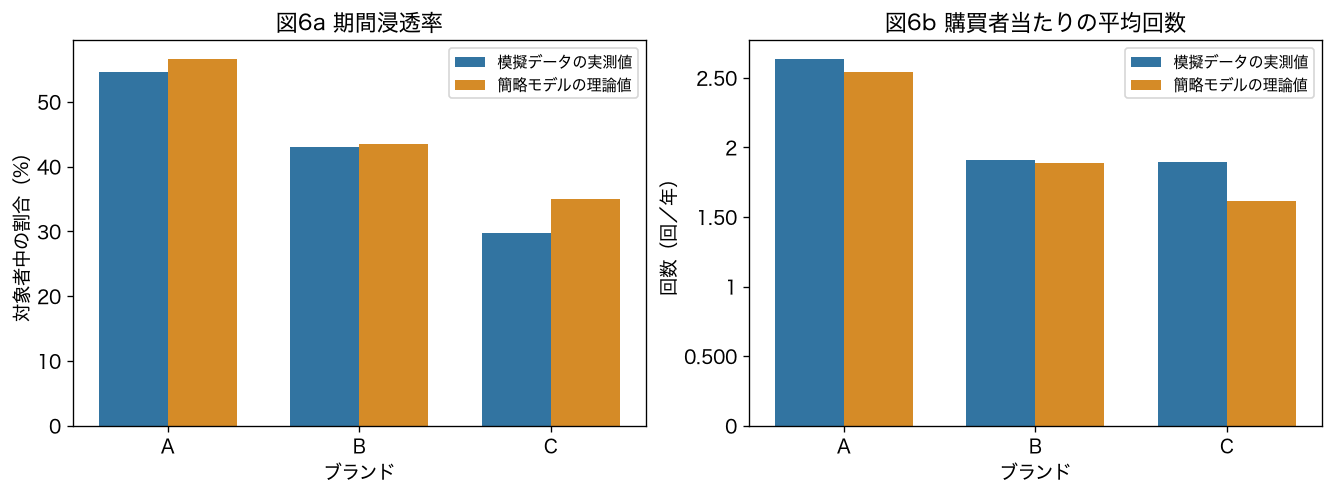

In [14]:
shares = brand_counts.sum(axis=0) / x.sum()
brand_mean = M_hat * shares
b_simple = 1 - (K_hat / (K_hat + brand_mean))**K_hat
w_simple = brand_mean / b_simple
buyers = (brand_counts > 0).sum(axis=0)
b_observed = buyers / n_people
w_observed = brand_counts.sum(axis=0) / buyers

for j, brand in enumerate(brands):
    pprint({"ブランド": brand, "シェア（%）": sig3(100 * shares[j]),
            "浸透率：実測 / 簡略理論（%）": [sig3(100 * b_observed[j]),
                                               sig3(100 * b_simple[j])],
            "購買者当たり回数：実測 / 簡略理論": [sig3(w_observed[j]),
                                                 sig3(w_simple[j])]})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
positions = np.arange(len(brands))
for ax, obs, theory, title, ylabel in (
    (axes[0], 100 * b_observed, 100 * b_simple, "図6a 期間浸透率", "対象者中の割合（%）"),
    (axes[1], w_observed, w_simple, "図6b 購買者当たりの平均回数", "回数（回／年）"),
):
    ax.bar(positions - 0.180, obs, width=0.360, color=COLORS[0], label="模擬データの実測値")
    ax.bar(positions + 0.180, theory, width=0.360, color=COLORS[1], label="簡略モデルの理論値")
    ax.set(xticks=positions, xticklabels=brands, xlabel="ブランド", ylabel=ylabel, title=title)
    ax.legend(fontsize=9)
save_svg(fig, "06_brand_comparison.svg")

ブランドCの期間浸透率は実測29.8%、簡略モデル35.0%で、購買者当たり回数は実測1.89回、理論値1.61回となる。この差には標本のばらつきと簡略化の影響が含まれる。高い回数だけから、強い愛着や施策の成果を読み取ることはできない。

最後に、本文の理論例と同じ5ブランド、$M=4$、$K=0.800$、$\alpha_0=10$でダブルジョパディを描く。これは推定結果ではなく、条件を固定した理論計算である。簡略モデルも重ね、二つの計算が一致しないことを確認する。

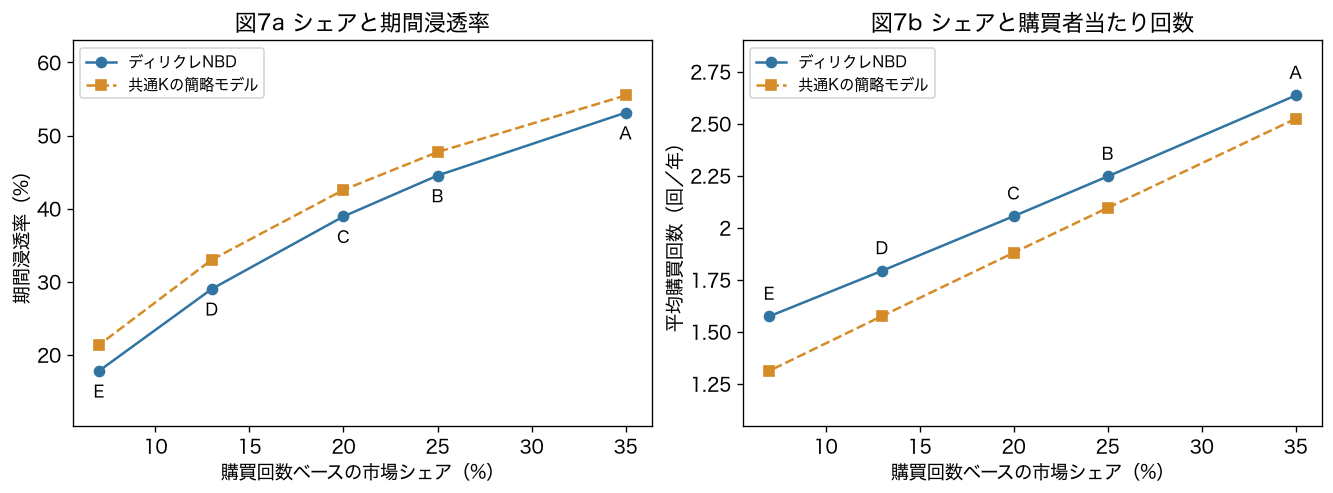

ディリクレNBDの理論値（AからEの順）
{'浸透率（%）': ['53.1', '44.5', '38.9', '29.0', '17.8'],
 '購買者当たりの平均回数': ['2.64', '2.25', '2.06', '1.79', '1.57']}


In [15]:
example_shares = np.array([0.350, 0.250, 0.200, 0.130, 0.0700])
example_brands = ["A", "B", "C", "D", "E"]
M_example, K_example, alpha0_example = 4, 0.800, 10

# 超幾何関数で、選択確率の個人差を含めた期間浸透率を求める。
b_full = 1 - special.hyp2f1(
    K_example, alpha0_example * example_shares, alpha0_example, -M_example / K_example
)
w_full = M_example * example_shares / b_full
b_approx = 1 - (K_example / (K_example + M_example * example_shares))**K_example
w_approx = M_example * example_shares / b_approx

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, full, simple, title, ylabel in (
    (axes[0], 100 * b_full, 100 * b_approx, "図7a シェアと期間浸透率", "期間浸透率（%）"),
    (axes[1], w_full, w_approx, "図7b シェアと購買者当たり回数", "平均購買回数（回／年）"),
):
    ax.plot(100 * example_shares, full, "o-", color=COLORS[0], label="ディリクレNBD")
    ax.plot(100 * example_shares, simple, "s--", color=COLORS[1], label="共通Kの簡略モデル")
    for brand, share, value in zip(example_brands, example_shares, full):
        offset = (0, 10) if ax is axes[1] else (0, -16)
        ax.annotate(brand, (100 * share, value), xytext=offset,
                    textcoords="offset points", ha="center", fontsize=10)
    ax.set(title=title, xlabel="購買回数ベースの市場シェア（%）", ylabel=ylabel)
    ax.margins(y=0.200)
    ax.legend(fontsize=9)
save_svg(fig, "07_double_jeopardy.svg")

print("ディリクレNBDの理論値（AからEの順）")
pprint({"浸透率（%）": [sig3(value * 100) for value in b_full],
        "購買者当たりの平均回数": [sig3(value) for value in w_full]})

シェア35%のAは浸透率53.1%、購買者当たり2.64回、シェア7%のEは17.8%、1.57回となる。ブランド間の回数の差を、規模の違いと併せて読める。

## 結論

この記事では、NBDとディリクレ分布で購買行動を表し、Pythonで購買回数と期間浸透率の比較基準を計算した。

分析では0回購買者、観察期間、対象者の範囲をそろえる。実測値と理論値の差は、配荷や認知、初回購買、再購買を追加で調べる手がかりとなる。実務では標本のばらつきも確認し、施策の効果は比較対象を設けて検証する。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)では、こうした課題設定から理論、実装、結果の読み方までを扱う。第5章の[コード全体と補足の導出](https://github.com/gihyo-book/marketing_science_book/tree/main/05)も公開されている。本記事で扱ったモデルを、実務のデータにどう当てはめるかを確認する際に参照できる。